In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import warnings 
warnings.filterwarnings('ignore')

In [3]:
titanic = pd.read_csv(r"C:\Users\Bibhu\Downloads\titanic dataset.csv")
titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
titanic.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [6]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
# as these things donot affect to predict the survival rate of people in this accident
d=titanic.drop(['Cabin','Name','Ticket','PassengerId'],axis=1)

In [8]:
for i in d.columns:
    print(i,":","\n",d[i].unique())


Survived : 
 [0 1]
Pclass : 
 [3 1 2]
Sex : 
 ['male' 'female']
Age : 
 [22.   38.   26.   35.     nan 54.    2.   27.   14.    4.   58.   20.
 39.   55.   31.   34.   15.   28.    8.   19.   40.   66.   42.   21.
 18.    3.    7.   49.   29.   65.   28.5   5.   11.   45.   17.   32.
 16.   25.    0.83 30.   33.   23.   24.   46.   59.   71.   37.   47.
 14.5  70.5  32.5  12.    9.   36.5  51.   55.5  40.5  44.    1.   61.
 56.   50.   36.   45.5  20.5  62.   41.   52.   63.   23.5   0.92 43.
 60.   10.   64.   13.   48.    0.75 53.   57.   80.   70.   24.5   6.
  0.67 30.5   0.42 34.5  74.  ]
SibSp : 
 [1 0 3 4 2 5 8]
Parch : 
 [0 1 2 5 3 4 6]
Fare : 
 [  7.25    71.2833   7.925   53.1      8.05     8.4583  51.8625  21.075
  11.1333  30.0708  16.7     26.55    31.275    7.8542  16.      29.125
  13.      18.       7.225   26.       8.0292  35.5     31.3875 263.
   7.8792   7.8958  27.7208 146.5208   7.75    10.5     82.1708  52.
   7.2292  11.2417   9.475   21.      41.5792  15.5     

In [9]:
d.describe(include='all')

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN


In [10]:
d.Age=titanic.Age.fillna(29.699118)

In [11]:
d.Embarked=titanic.Embarked.replace(np.nan,'Q')

In [12]:
d.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [13]:
for i in d.columns:
    print(i,":","\n",d[i].unique())


Survived : 
 [0 1]
Pclass : 
 [3 1 2]
Sex : 
 ['male' 'female']
Age : 
 [22.       38.       26.       35.       29.699118 54.        2.
 27.       14.        4.       58.       20.       39.       55.
 31.       34.       15.       28.        8.       19.       40.
 66.       42.       21.       18.        3.        7.       49.
 29.       65.       28.5       5.       11.       45.       17.
 32.       16.       25.        0.83     30.       33.       23.
 24.       46.       59.       71.       37.       47.       14.5
 70.5      32.5      12.        9.       36.5      51.       55.5
 40.5      44.        1.       61.       56.       50.       36.
 45.5      20.5      62.       41.       52.       63.       23.5
  0.92     43.       60.       10.       64.       13.       48.
  0.75     53.       57.       80.       70.       24.5       6.
  0.67     30.5       0.42     34.5      74.      ]
SibSp : 
 [1 0 3 4 2 5 8]
Parch : 
 [0 1 2 5 3 4 6]
Fare : 
 [  7.25    71.2833   7.925   53.

In [14]:
for i in d.columns:
    print(i,':','\n',d[i].unique())
    

Survived : 
 [0 1]
Pclass : 
 [3 1 2]
Sex : 
 ['male' 'female']
Age : 
 [22.       38.       26.       35.       29.699118 54.        2.
 27.       14.        4.       58.       20.       39.       55.
 31.       34.       15.       28.        8.       19.       40.
 66.       42.       21.       18.        3.        7.       49.
 29.       65.       28.5       5.       11.       45.       17.
 32.       16.       25.        0.83     30.       33.       23.
 24.       46.       59.       71.       37.       47.       14.5
 70.5      32.5      12.        9.       36.5      51.       55.5
 40.5      44.        1.       61.       56.       50.       36.
 45.5      20.5      62.       41.       52.       63.       23.5
  0.92     43.       60.       10.       64.       13.       48.
  0.75     53.       57.       80.       70.       24.5       6.
  0.67     30.5       0.42     34.5      74.      ]
SibSp : 
 [1 0 3 4 2 5 8]
Parch : 
 [0 1 2 5 3 4 6]
Fare : 
 [  7.25    71.2833   7.925   53.

<Axes: xlabel='Pclass', ylabel='count'>

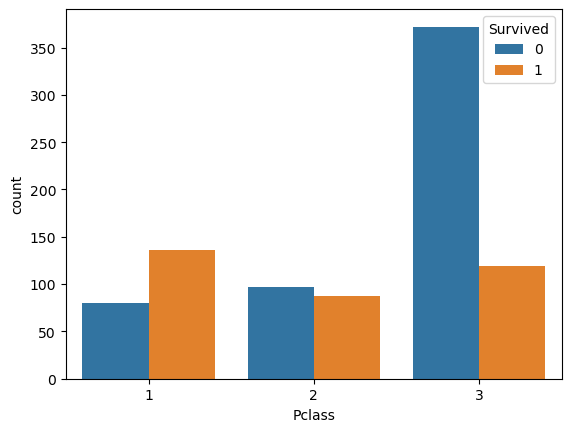

In [15]:
,# showing relationship between pclasss and output
sns.countplot(x=d.Pclass,hue=d.Survived)

<Axes: xlabel='Sex', ylabel='count'>

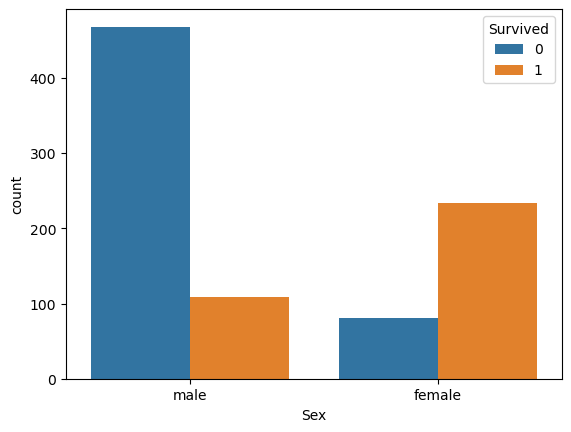

In [16]:
,# showing relationship between pclasss and output
sns.countplot(x=d.Sex,hue=d.Survived )

<Axes: xlabel='Sex'>

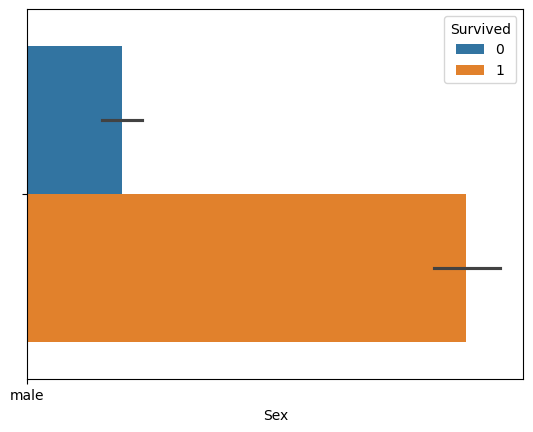

In [17]:
sns.barplot(x=d.Sex,hue=d.Survived ) 

<Axes: xlabel='Survived', ylabel='Age'>

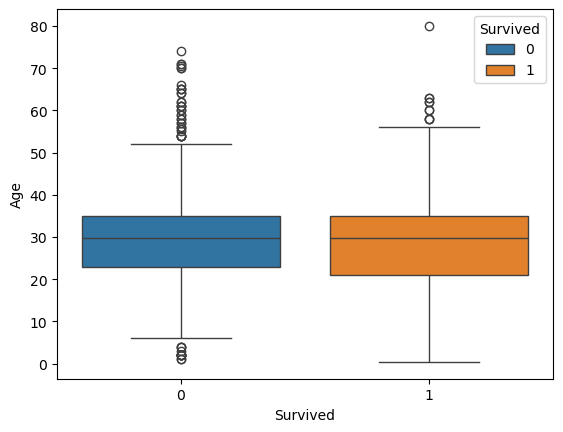

In [18]:
sns.boxplot(x=d.Survived , y=d.Age,hue=d.Survived ) 

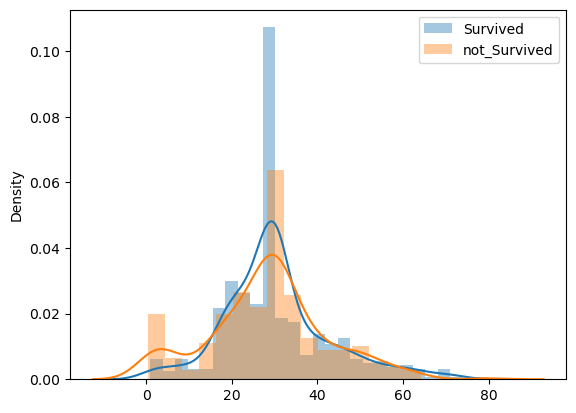

In [19]:
sns.distplot(x=d.Age[d.Survived==0],label='Survived' ) 
sns.distplot(x=d.Age[d.Survived==1],label='not_Survived')
plt.legend() # servived  blue color & yellow for not_servived
plt.show()

<Axes: xlabel='SibSp', ylabel='count'>

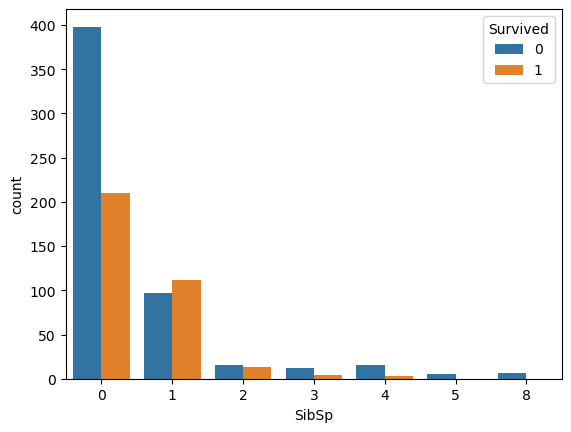

In [20]:
sns.countplot(x=d.SibSp ,hue=d.Survived )

<Axes: xlabel='Embarked', ylabel='count'>

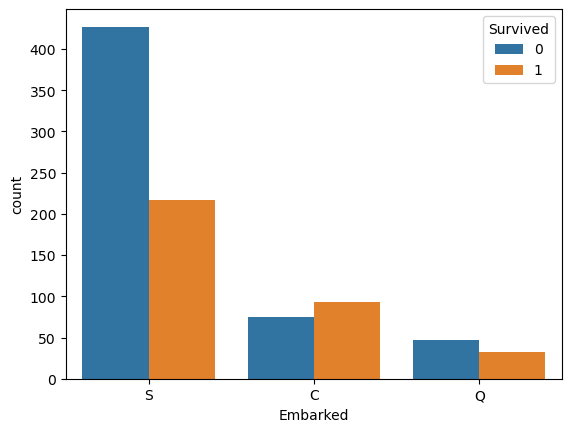

In [21]:
sns.countplot(x=d.Embarked  ,hue=d.Survived  )

In [22]:
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()

d.Sex=le.fit_transform(d.Sex)


In [23]:
le.inverse_transform([1,0])

array(['male', 'female'], dtype=object)

In [24]:
le2=LabelEncoder()
d.Embarked =le2.fit_transform(d.Embarked )

<Axes: >

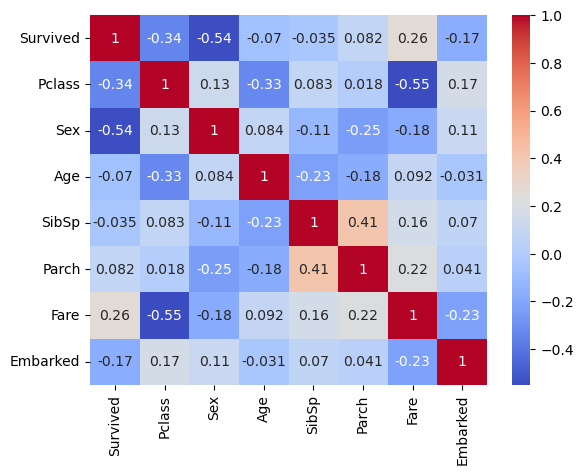

In [25]:
c=d.corr()
sns.heatmap(c,annot=True,cmap='coolwarm')

<Axes: >

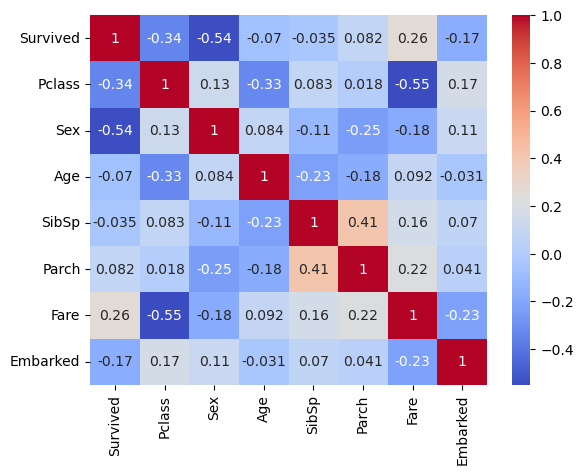

In [26]:
# Option 1: Plot the correlation matrix (most common use case for heatmaps)
sns.heatmap(d.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm')

# Option 2: Select only specific numeric columns you want to inspect
# sns.heatmap(d[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex', 'Embarked']], annot=True, cmap='coolwarm')

In [27]:
ip=d.drop(['Survived'],axis=1)
ip

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,22.000000,1,0,7.2500,2
1,1,0,38.000000,1,0,71.2833,0
2,3,0,26.000000,0,0,7.9250,2
3,1,0,35.000000,1,0,53.1000,2
4,3,1,35.000000,0,0,8.0500,2
...,...,...,...,...,...,...,...
886,2,1,27.000000,0,0,13.0000,2
887,1,0,19.000000,0,0,30.0000,2
888,3,0,29.699118,1,2,23.4500,2
889,1,1,26.000000,0,0,30.0000,0


In [28]:
op=d.Survived
op

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [29]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

ct = ColumnTransformer([
    ('Sex', OneHotEncoder(), [1]),
    ('Embarked', OneHotEncoder(), [6])
], remainder='passthrough')

ip = np.array(ct.fit_transform(ip), dtype=str)

print(ip.shape)
print(ip)

(891, 10)
[['0.0' '1.0' '0.0' ... '1.0' '0.0' '7.25']
 ['1.0' '0.0' '1.0' ... '1.0' '0.0' '71.2833']
 ['1.0' '0.0' '0.0' ... '0.0' '0.0' '7.925']
 ...
 ['1.0' '0.0' '0.0' ... '1.0' '2.0' '23.45']
 ['0.0' '1.0' '1.0' ... '0.0' '0.0' '30.0']
 ['0.0' '1.0' '0.0' ... '0.0' '0.0' '7.75']]


In [30]:
from sklearn.model_selection import train_test_split

In [31]:
x_train,x_test,y_train,y_test=train_test_split(ip,op,train_size=0.8)

In [32]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.fit_transform(x_test)

In [33]:
from sklearn.linear_model import LogisticRegression

lr=LogisticRegression()


lr.fit(x_train,y_train)

LogisticRegression()

In [34]:
pred=lr.predict(x_test)
pred

array([0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 1, 0], dtype=int64)

In [35]:
# confusion matrix
from sklearn.metrics import  confusion_matrix, ConfusionMatrixDisplay

cm=confusion_matrix(y_test,pred)
print(cm)

[[96  9]
 [21 53]]


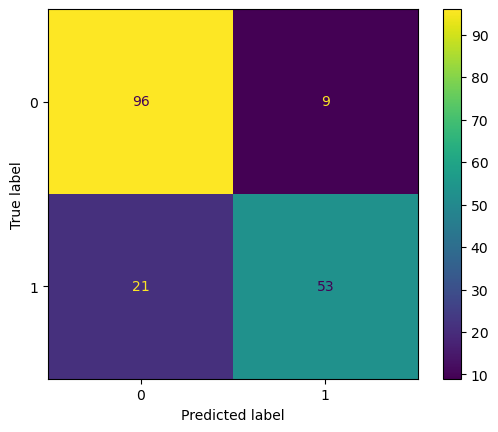

In [36]:
cm=ConfusionMatrixDisplay(cm)
cm.plot()
plt.show()

In [37]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score

acc = accuracy_score(y_test, pred)
recall = recall_score(y_test, pred, average='macro')
f1 = f1_score(y_test, pred, average='macro')
precision = precision_score(y_test, pred, average='macro')

print("Accuracy:", acc)
print("Recall score:", recall)
print("F1 score:", f1)
print("Precision score:", precision)

Accuracy: 0.8324022346368715
Recall score: 0.8152509652509652
F1 score: 0.8221383147853736
Precision score: 0.8376757650951199


In [38]:
from sklearn.naive_bayes import GaussianNB


nb = GaussianNB()
nb.fit(x_train, y_train)



GaussianNB()

In [39]:
pred_nb = nb.predict(x_test)

In [40]:
pred_nb

array([0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 1, 0], dtype=int64)

In [41]:
# confusion matrix
from sklearn.metrics import  confusion_matrix, ConfusionMatrixDisplay

cm=confusion_matrix(y_test,pred_nb)
print(cm)

[[90 15]
 [18 56]]


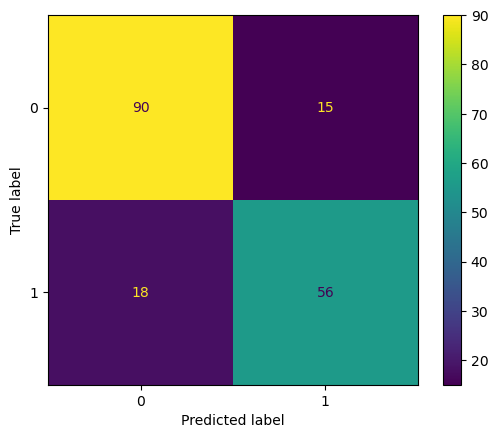

In [42]:
cm=ConfusionMatrixDisplay(cm)
cm.plot()
plt.show()

In [43]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score

acc1 = accuracy_score(y_test, pred_nb)
recall1 = recall_score(y_test, pred_nb, average='macro')
f11 = f1_score(y_test, pred_nb, average='macro')
precision1 = precision_score(y_test, pred_nb, average='macro')

print("Accuracy:", acc1)
print("Recall score:", recall1)
print("F1 score:", f11)
print("Precision score:", precision1)

Accuracy: 0.8156424581005587
Recall score: 0.8069498069498069
F1 score: 0.8087421078193298
Precision score: 0.8110328638497653


In [44]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize and train the KNN classifier (default uses k=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)



KNeighborsClassifier()

In [45]:
# Make predictions
pred_knn = knn.predict(x_test)

In [46]:
from sklearn.metrics import  confusion_matrix, ConfusionMatrixDisplay

cm=confusion_matrix(y_test,pred_knn)
print(cm)

[[92 13]
 [19 55]]


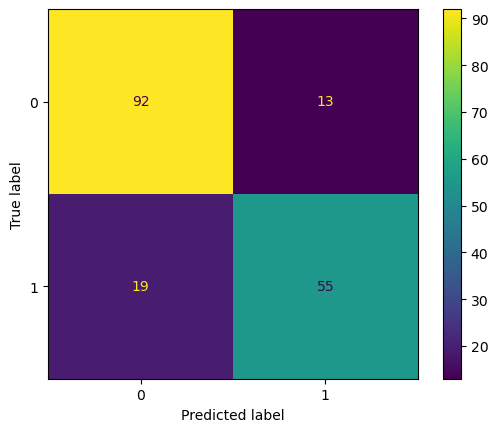

In [47]:
cm=ConfusionMatrixDisplay(cm)
cm.plot()
plt.show()

In [48]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score

acc2 = accuracy_score(y_test, pred_knn)
recall2 = recall_score(y_test, pred_knn, average='macro')
f12 = f1_score(y_test, pred_knn, average='macro')
precision2 = precision_score(y_test, pred_knn, average='macro')

print("Accuracy:", acc2)
print("Recall score:", recall2)
print("F1 score:", f12)
print("Precision score:", precision2)

Accuracy: 0.8212290502793296
Recall score: 0.8097168597168597
F1 score: 0.8132498695878978
Precision score: 0.8188261791202968


In [49]:
from sklearn.svm import SVC

# Initialize and train the Support Vector Classifier
svm = SVC(kernel='rbf',C=100,gamma=0.01)  # 'rbf' is a popular default kernel for non-linear data
svm.fit(x_train, y_train)



SVC(C=100, gamma=0.01)

In [50]:
# Make predictions
pred_svm = svm.predict(x_test)

In [51]:
pred_svm

array([0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 0], dtype=int64)

In [52]:
from sklearn.metrics import  confusion_matrix, ConfusionMatrixDisplay

cm=confusion_matrix(y_test,pred_svm)
print(cm)

[[100   5]
 [ 24  50]]


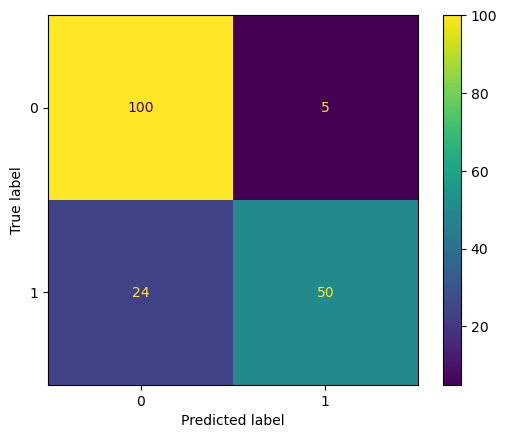

In [53]:
cm=ConfusionMatrixDisplay(cm)
cm.plot()
plt.show()

In [54]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score

acc3 = accuracy_score(y_test, pred_svm)
recall3 = recall_score(y_test, pred_svm, average='macro')
f13 = f1_score(y_test, pred_svm, average='macro')
precision3 = precision_score(y_test, pred_svm, average='macro')

print("Accuracy:", acc3)
print("Recall score:", recall3)
print("F1 score:", f13)
print("Precision score:", precision3)

Accuracy: 0.8379888268156425
Recall score: 0.814028314028314
F1 score: 0.8242781219322298
Precision score: 0.8577712609970674


In [55]:
from sklearn.tree import DecisionTreeClassifier


clf = DecisionTreeClassifier(criterion='entropy')


clf.fit(x_train, y_train)



DecisionTreeClassifier(criterion='entropy')

In [56]:

pred_dt = clf.predict(x_test)

In [57]:
from sklearn.metrics import accuracy_score,recall_score,f1_score,precision_score


acc_dt = accuracy_score(y_test, pred_dt)
recall_dt = recall_score(y_test, pred_dt, average='macro')
f1_dt = f1_score(y_test, pred_dt, average='macro')
precision_dt = precision_score(y_test, pred_dt, average='macro')

print("Accuracy:", acc_dt)
print("Recall score:", recall_dt)
print("F1 score:", f1_dt)
print("Precision score:", precision_dt)



Accuracy: 0.8156424581005587
Recall score: 0.792985842985843
F1 score: 0.8013585768571141
Precision score: 0.8273655450100661


In [58]:
from sklearn.ensemble import RandomForestClassifier

clf1=RandomForestClassifier(criterion='entropy',random_state=0)

clf1.fit(x_train,y_train)

RandomForestClassifier(criterion='entropy', random_state=0)

In [59]:
pred_rf=clf1.predict(x_test)

In [60]:
from sklearn.metrics import accuracy_score,recall_score,f1_score,precision_score


acc_pp = accuracy_score(y_test, pred_rf)
recall_pp = recall_score(y_test, pred_rf, average='macro')
f1_pp = f1_score(y_test, pred_rf, average='macro')
precision_pp = precision_score(y_test, pred_rf, average='macro')

print("Accuracy:", acc_pp)
print("Recall score:", recall_pp)
print("F1 score:", f1_pp)
print("Precision score:", precision_pp)

Accuracy: 0.8212290502793296
Recall score: 0.8017374517374517
F1 score: 0.8091684434968016
Precision score: 0.8283613445378151


In [61]:
# AdaBoostClassifier
from sklearn.ensemble import AdaBoostClassifier
a1=AdaBoostClassifier(n_estimators=50,learning_rate=0.1)
a1.fit(x_train,y_train)

AdaBoostClassifier(learning_rate=0.1)

In [62]:
pre_esm=a1.predict(x_test)


In [63]:
pre_esm

array([0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 1, 0], dtype=int64)

In [64]:
from sklearn.metrics import accuracy_score,recall_score,f1_score,precision_score


acc_pp2 = accuracy_score(y_test, pre_esm)
recall_pp2 = recall_score(y_test, pre_esm, average='macro')
f1_pp2 = f1_score(y_test, pre_esm, average='macro')
precision_pp2 = precision_score(y_test, pre_esm, average='macro')

print("Accuracy:", acc_pp2)
print("Recall score:", recall_pp2)
print("F1 score:", f1_pp2)
print("Precision score:", precision_pp2)

Accuracy: 0.8379888268156425
Recall score: 0.816023166023166
F1 score: 0.8254363251168577
Precision score: 0.8531061259706644


In [65]:
# adaboost estimator
from sklearn.ensemble import AdaBoostClassifier
a2=AdaBoostClassifier(n_estimators=50,learning_rate=0.1,estimator=clf1)
a2.fit(x_train,y_train)

AdaBoostClassifier(estimator=RandomForestClassifier(criterion='entropy',
                                                    random_state=0),
                   learning_rate=0.1)

In [66]:
pred_b=a2.predict(x_test)

In [67]:
from sklearn.metrics import accuracy_score,recall_score,f1_score,precision_score


acc_pp2 = accuracy_score(y_test, pred_b)
recall_pp2 = recall_score(y_test, pred_b, average='macro')
f1_pp2 = f1_score(y_test, pred_b, average='macro')
precision_pp2 = precision_score(y_test, pred_b, average='macro')

print("Accuracy:", acc_pp2)
print("Recall score:", recall_pp2)
print("F1 score:", f1_pp2)
print("Precision score:", precision_pp2)

Accuracy: 0.8212290502793296
Recall score: 0.8037323037323038
F1 score: 0.8102808691043986
Precision score: 0.8253377446925834


In [68]:
# gradientboost algorithm 
from sklearn.ensemble import GradientBoostingClassifier
a3=GradientBoostingClassifier(n_estimators=20,learning_rate=0.1)
a3.fit(x_train,y_train)

GradientBoostingClassifier(n_estimators=20)

In [69]:
yp8=a3.predict(x_test)

In [70]:
yp8

array([0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 1, 0], dtype=int64)

In [71]:
from sklearn.metrics import accuracy_score,recall_score,f1_score,precision_score


acc_pp3 = accuracy_score(y_test, yp8)
recall_pp3 = recall_score(y_test, yp8, average='macro')
f1_pp3 = f1_score(y_test, yp8, average='macro')
precision_pp3 = precision_score(y_test, yp8, average='macro')

print("Accuracy:", acc_pp3)
print("Recall score:", recall_pp3)
print("F1 score:", f1_pp3)
print("Precision score:", precision_pp3)

Accuracy: 0.8324022346368715
Recall score: 0.8072715572715572
F1 score: 0.8175951086956521
Precision score: 0.8537037037037037
